### Funzioni

In [77]:
import numpy as np
import matplotlib.pyplot as plt

In [78]:
def input_data(file, Arduino=False):

    if Arduino:
        t, V = np.loadtxt(file, unpack=True)
    else:
        t, _, V, _ = np.loadtxt(file, unpack=True)

    return t,V

In [79]:
def do_FFT(t,V, Arduino=False):
    N = len(V)
    dt = t[1] - t[0] 
    if Arduino: 
        dt= dt * 1e-6          #  Arduino prende in micros
    freq = np.fft.rfftfreq(N, d=dt)
    ASD = np.abs(np.fft.rfft(V))

    return freq, ASD

In [80]:
def peaks(freq, ASD):
    
    peak_indices = []

    for i in range(1, len(ASD)-1):
        if ASD[i] > ASD[i-1] and ASD[i] > ASD[i+1] and ASD[i] > 1:
            peak_indices.append(i)

    print('Peaks: \n')
    for i in peak_indices:
        print(freq[i], ASD[i])
    
    peak_freqs = [freq[i] for i in peak_indices]

    return peak_freqs

In [81]:
def plot_ASD(t,V, freq, ASD, peak_freqs, peak_idx, maxf, log=True):

    fig, axes = plt.subplots(nrows=2, ncols=1, constrained_layout=True, figsize = (12,6*2))
    
    axes[0].plot(t,V)
    axes[0].set_xlabel("Tempo [s]")
    axes[0].set_ylabel("Segnale [digit]")
    axes[0].grid()

    axes[1].plot(freq, ASD)
    axes[1].set_xlabel("Frequenza [Hz]")
    axes[1].set_ylabel("ASD [u.a.]")
    axes[1].grid()

    if log:
        axes[1].set_yscale("log")

    if maxf == None:
        maxf = peak_freqs[-1]

    axes[1].set_xlim(0, maxf)

    if peak_idx != None:
        peak_freqs = [peak_freqs[i] for i in peak_idx]


    for p in peak_freqs:
        idx = np.argmin(np.abs(freq - p))
        axes[1].annotate(f"{p:.0f} Hz",
                    xy=(freq[idx], ASD[idx]),
                    xytext=(freq[idx] +20, ASD[idx] *1.1 ),
                    arrowprops=dict(arrowstyle='-', lw=0.8),
                    fontsize=9)
    
    plt.show()
    return

In [82]:
def do_all(file, Arduino=False, peak_idx=None, maxf=None, log=True):
    t,V = input_data(file, Arduino=Arduino)
    freq, ASD = do_FFT(t,V, Arduino=Arduino)
    peak_freqs= peaks(freq, ASD)
    plot_ASD(t,V,freq,ASD, peak_freqs, peak_idx, maxf, log=log)
    return

### Esperimenti Arduino

In [83]:
dirname = '/home/gea/Desktop/Lab_2/AliceGea/Esperienza_'

#### Quadra

Peaks: 

14.70726656626506 6972.210016110112
20.590173192771083 10122.137613208863
38.23889307228916 12176.048086245703
47.06325301204819 21211.181912148233
70.59487951807229 2040008.7962043227
94.12650602409639 21412.683673273987
102.95086596385542 12290.976187298944
108.83377259036145 10463.298295697903
120.59958584337349 8743.425668550923
126.48249246987952 8309.255277726603
138.24830572289156 9874.096389695409
144.1312123493976 7884.000743223824
150.0141189759036 8122.2456702810805
155.89702560240963 7237.9712303224005
161.77993222891567 8294.75022561043
173.54574548192772 10144.28454268347
179.42865210843374 12105.621519363907
188.25301204819277 18263.46938451194
211.78463855421688 658876.8649549754
235.31626506024097 21649.532677203406
244.140625 11654.336068603188
258.84789156626505 8336.752866645893
279.43806475903614 8551.230409225102
285.3209713855422 8823.872570869338
291.2038780120482 7057.799564046538
297.0867846385542 6384.528739015659
302.96969126506025 8422.02433768801


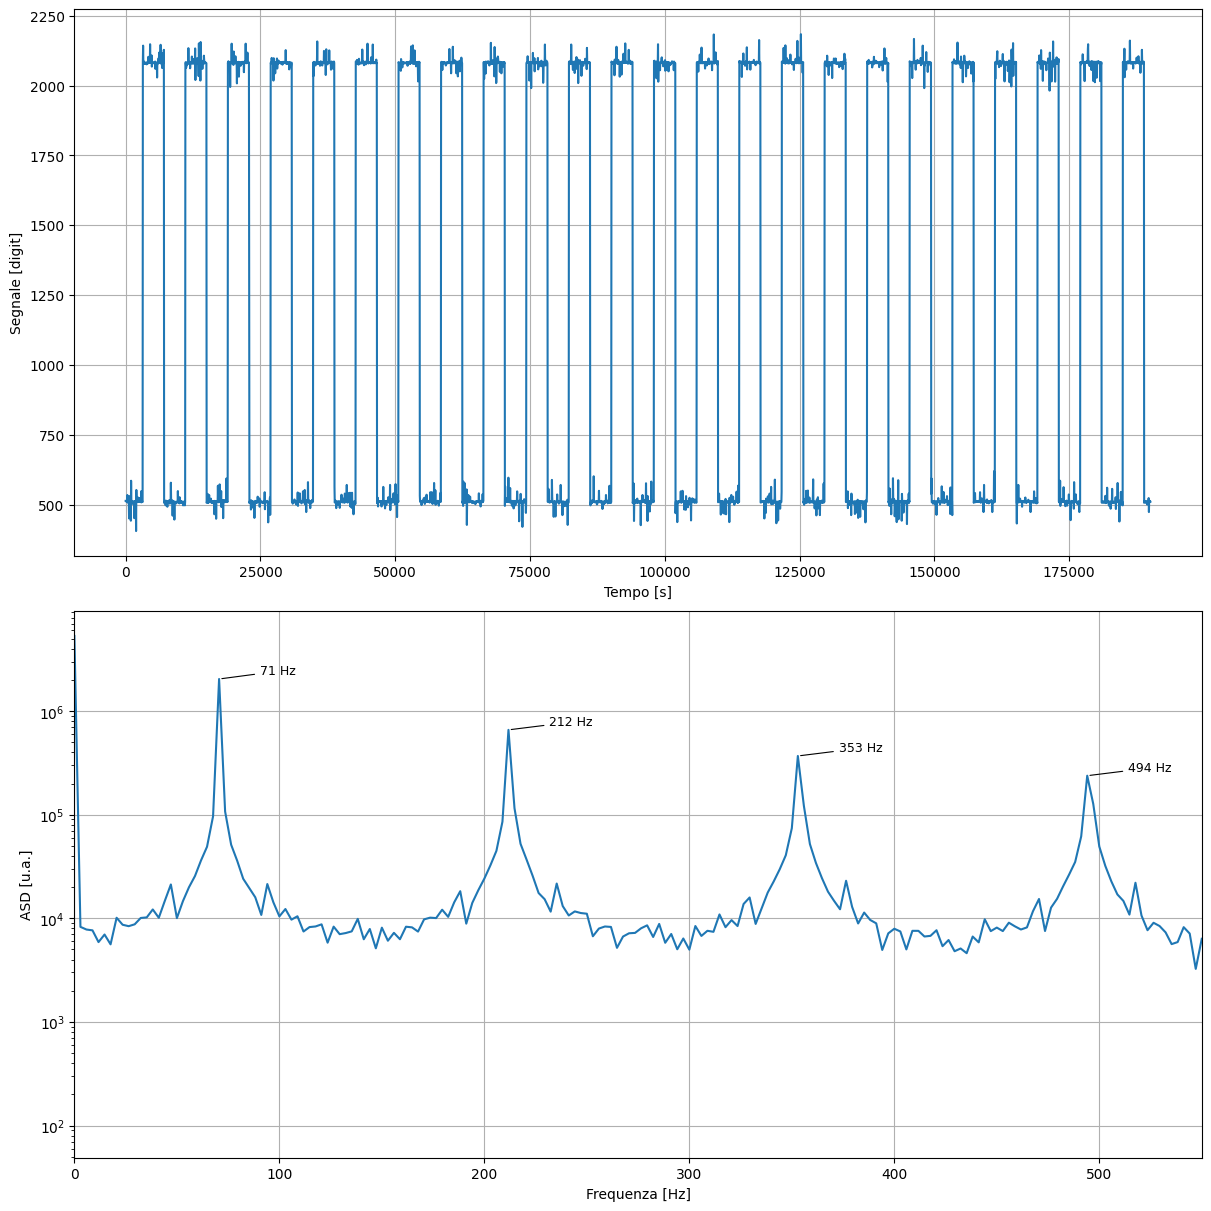

In [84]:
file = dirname+'5/Per_prossimo_esperimento/data_quadra.txt'
idx = [4, 18, 31, 44]
maxf = 550
do_all(file, Arduino=True, peak_idx=idx, maxf=maxf)

#### Quadra asymm

Peaks: 

9.212853773584905 9952.299027316374
23.032134433962263 3864.9362896093194
36.85141509433962 7341.85035256314
59.883549528301884 7446.206282801879
82.91568396226415 6932.907706339675
96.73496462264151 14485.800725885641
105.94781839622641 22820.103612216295
133.58637971698113 5957.247858353834
142.79923349056602 5556.665199825931
161.22494103773585 5276.24000556264
170.43779481132074 9154.41851310081
202.68278301886792 47128.95158272099
230.32134433962264 4193.449912991842
239.53419811320754 3984.2962760193386
257.95990566037733 1999.0991403917283
267.17275943396226 4630.061568489558
294.811320754717 8514.147813888834
313.23702830188677 18990.370740042006
345.48201650943395 9678.790520239007
354.6948702830189 6425.237897156418
363.90772405660374 7267.836039839742
382.3334316037736 8444.829703907651
391.54628537735846 8121.728661936964
409.9719929245283 18135.286797380053
419.1848466981132 22404.786290443048
437.610554245283 12930.160619106235
451.42983490566036 15780.4249041525

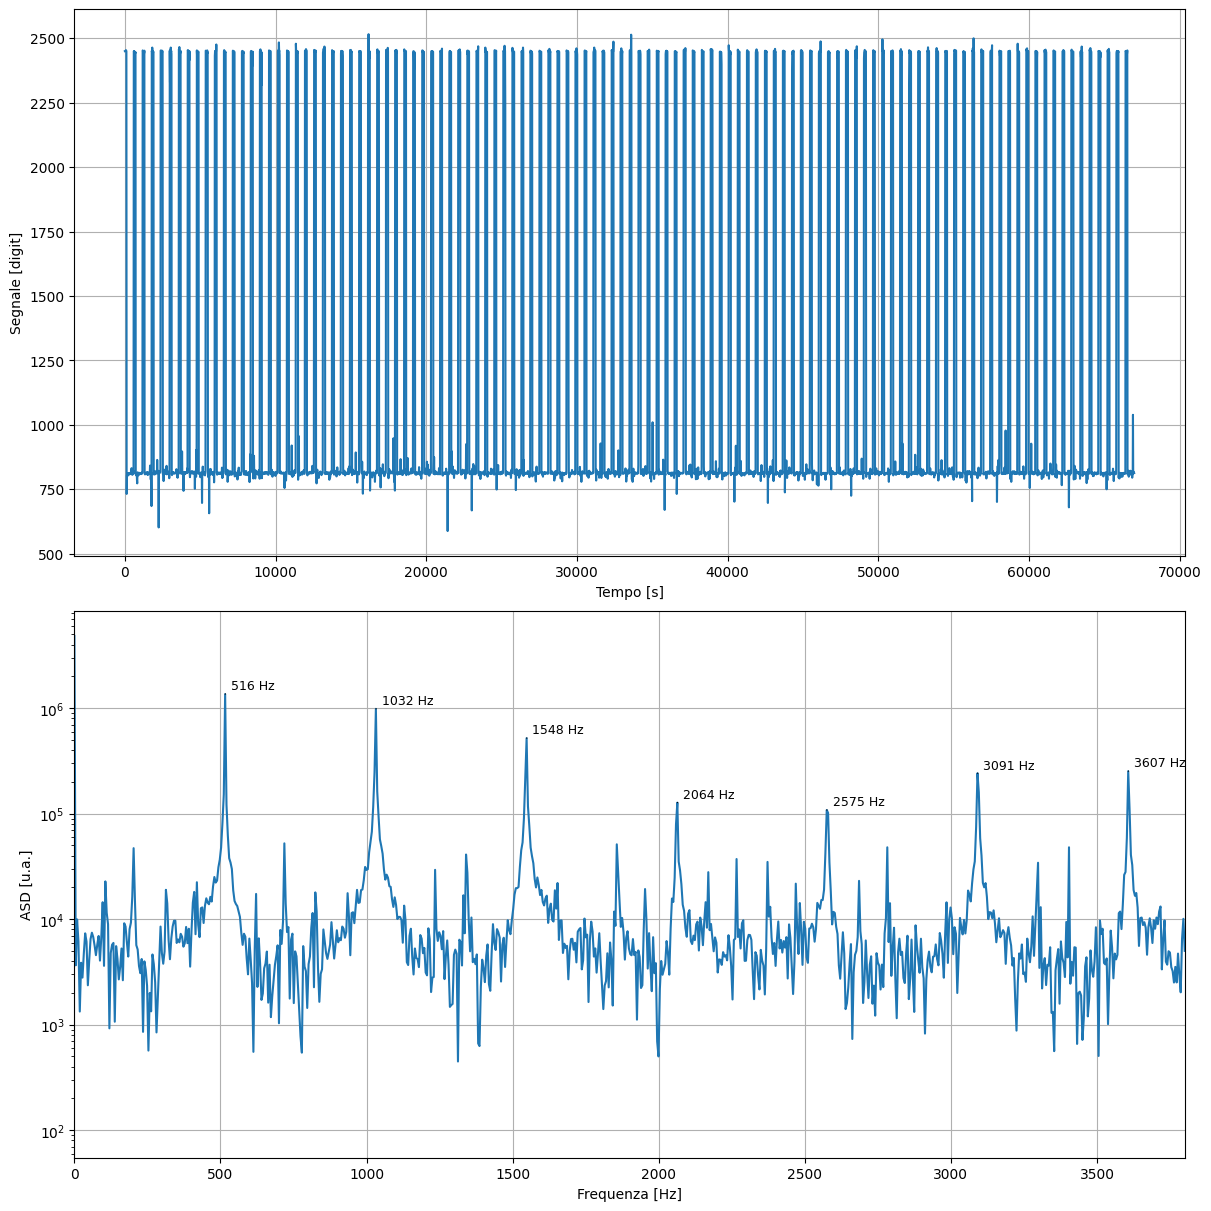

In [90]:
file = dirname+'5/Per_prossimo_esperimento/data_quadra_asymm.txt'
idx = [29, 54, 81, 115, 148, 176, 211]
maxf = 3800
do_all(file, Arduino=True, peak_idx=idx, maxf=maxf)

#### triangolare

Peaks: 

11.909298780487804 5077.850434400152
17.863948170731707 4909.919156050012
35.72789634146341 7021.205983715277
41.682545731707314 7174.220946351915
50.614519817073166 9256.380873613642
71.45579268292683 1234915.7112400031
110.16101371951218 4808.809630689987
122.07031249999999 3612.093886080751
133.9796112804878 3259.496854248018
139.9342606707317 2586.5952862207073
148.86623475609755 1938.2186292662172
154.82088414634146 1978.413540061403
166.73018292682926 2882.4925086702456
172.68483231707316 2600.6233391981755
181.616806402439 2659.998563750587
196.50342987804876 2947.3817646147468
214.36737804878047 125274.35233260864
238.18597560975607 4540.120717300155
247.11794969512192 4192.914701294111
264.9818978658536 3056.0852082021834
276.8911966463414 2955.5131181361608
285.8231707317073 2938.9419112488845
291.7778201219512 2077.0509727364706
300.70979420731703 2885.335226723952
306.66444359756093 2487.755412506222
315.5964176829268 1997.542341496866
324.52839176829264 3269.40476

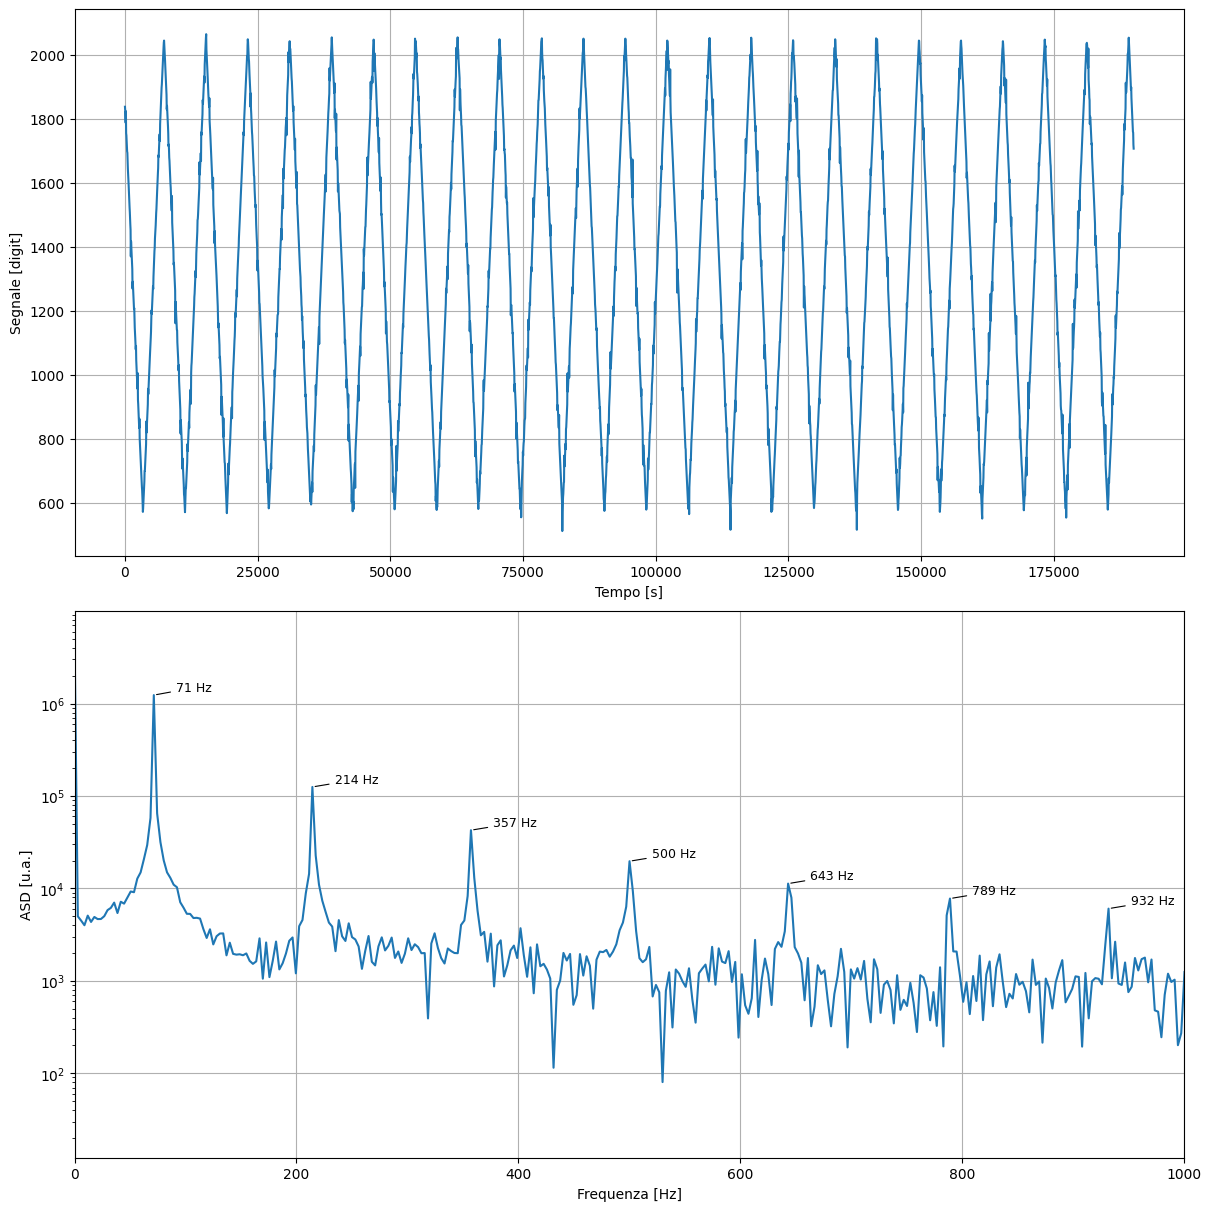

In [93]:
file = dirname+'5/Per_prossimo_esperimento/data_triangolo.txt'
idx = [5, 16, 28, 43, 58, 74, 90]
maxf = 1000
do_all(file, Arduino=True, peak_idx=idx, maxf=maxf)

### Use code

In [85]:
dirname = '/home/gea/Desktop/Lab_2/AliceGea/Esperienza_'

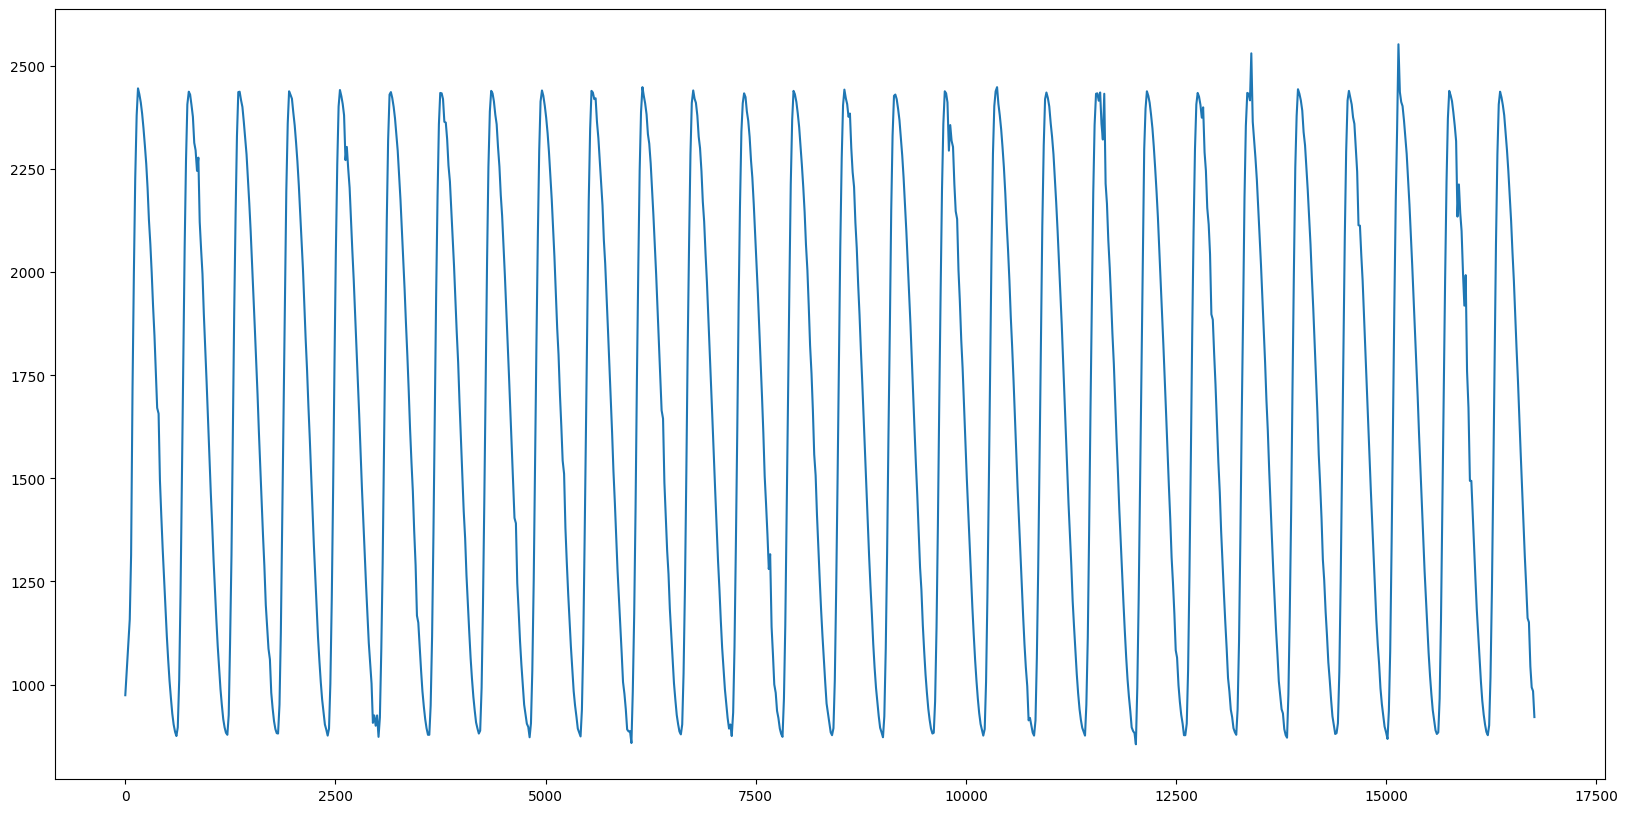

In [119]:
# Check

# file = dirname+'6/dati_natale/integratore_7.txt'
file = dirname+'5/Per_prossimo_esperimento/data_sin_asymm.txt'
t,V = input_data(file, Arduino=True)
plt.figure(figsize=(20, 10))
plt.plot(t,V)


Peaks: 

136.58216783216784 152569.0191098831
437.06293706293707 31093.290488908337
737.5437062937064 13597.37042743376
928.7587412587412 3911.7421124013217
1038.0244755244755 8305.663482426087
1174.6066433566434 3253.94478703645
1338.5052447552448 6083.049937211614
1475.0874125874127 2584.628654039457
1529.7202797202797 2173.833573098518
1638.986013986014 5094.109466953619
1775.5681818181818 2342.5831073421155
1884.8339160839162 1738.9019734399176
1939.4667832167831 3947.6596830602894
2021.4160839160838 1977.2954749033372
2185.3146853146854 1482.511350607348
2239.9475524475524 3248.8507568579416
2321.896853146853 2000.9312164134699
2376.52972027972 1779.270356142161
2458.479020979021 1487.8427299158539
2540.4283216783215 2619.052804201784
2677.0104895104896 1674.324742065265
2731.6433566433566 1591.312686532677
2840.909090909091 2257.9596757438558
2977.4912587412587 1779.9268540142618
3141.38986013986 2065.066119751881
3305.2884615384614 1557.4464883540375
3441.8706293706296 1882.0350

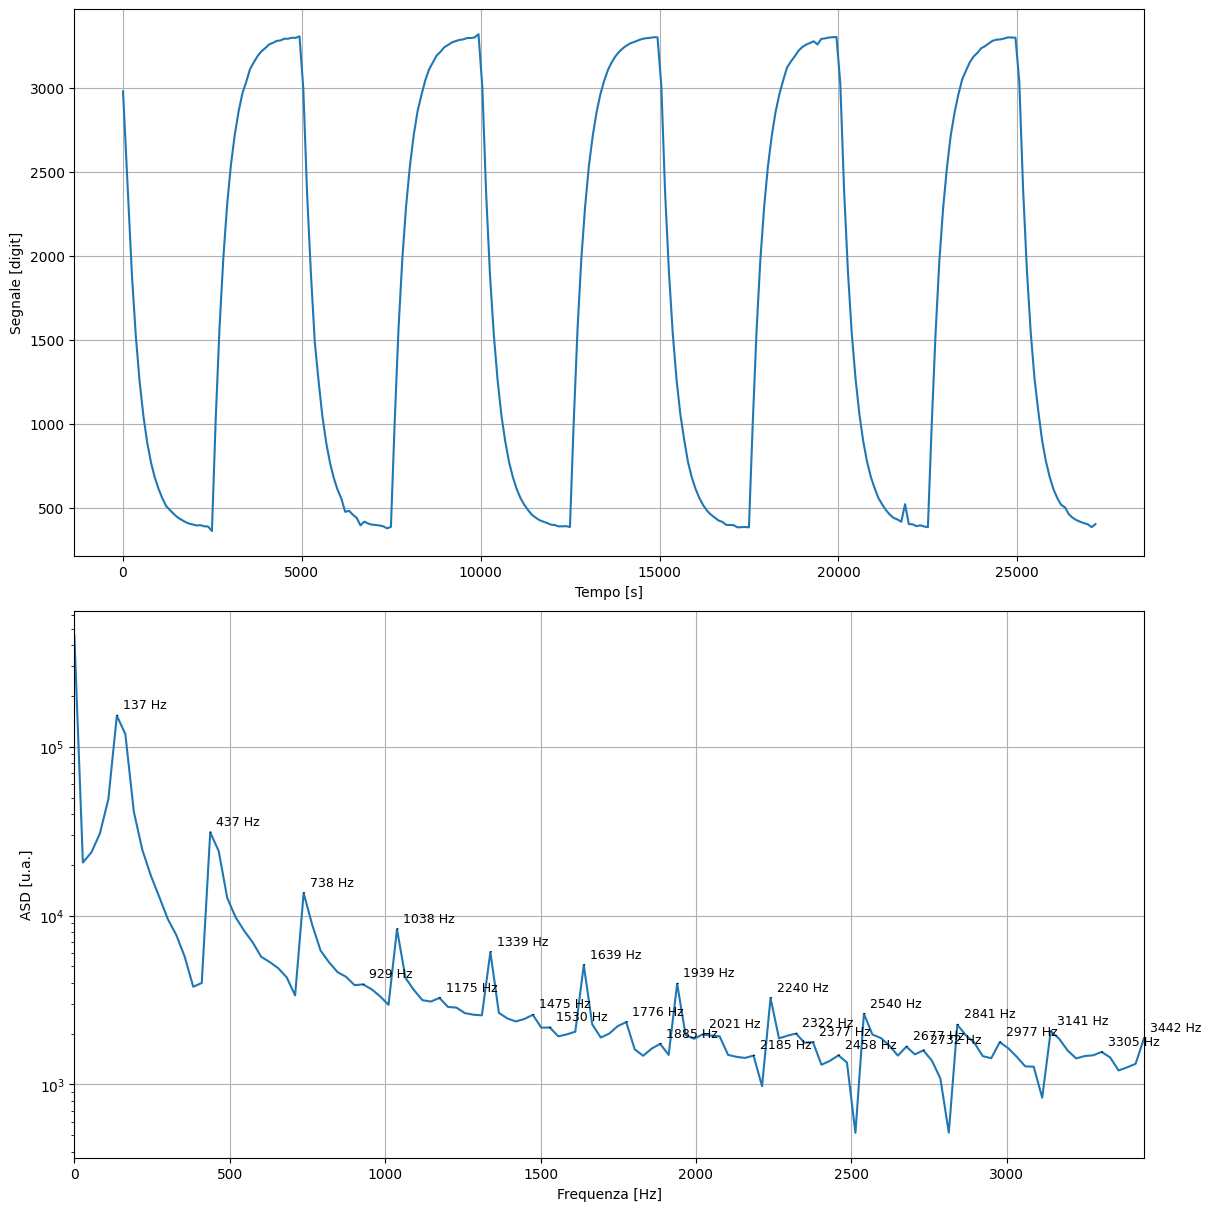

In [111]:
do_all(file, Arduino=True)

### Interpretare

mi servono freq e ASD dei picchi

**Casi**

solo un picco a f0: sinusoidale pura
solo armoniche dispari, con ampiezza A_n sim 1/n: quadra
solo armoniche dispari, con ampiezza A_n sim 1/n^2: triangolare
tutte le armoniche, ampiezza 1/n:pinna di squalo

| Segnale     | Armoniche presenti | Decadimento |
| ----------- | ------------------ | ----------- |
| Sinusoide   | solo (f_0)         | —           |
| Quadra      | solo dispari       | (1/n)       |
| Triangolare | solo dispari       | (1/n^2)     |
| Sawtooth    | tutte              | (1/n)       |


### Aliasing

Aliasing = campionare troppo lentamente → confondere una frequenza alta con una più bassa

👉 Il segnale viene “visto male” perché lo guardi troppo di rado.

👀 Intuizione visiva (tipo film)

Immagina una ruota che gira veloce:

se la filmi bene → vedi la rotazione giusta
se fai pochi frame → sembra:
più lenta
ferma
addirittura al contrario

👉 Questo è aliasing.

⚙️ Nel tuo caso

Hai:

t = np.linspace(0, 1000, 1000)

👉 quindi:

Δt ≈ 1 s
frequenza di campionamento:
fs=1 Hz
f
s
	​

=1 Hz

👉 limite massimo misurabile (Nyquist):

fmax=fs2=0.5 Hz
f
max
	​

=
2
f
s
	​

	​

=0.5 Hz
❗ Ma il tuo segnale è:
f=52π≈0.8 Hz
f=
2π
5
	​

≈0.8 Hz

👉 cioè più alto del massimo misurabile

💥 Cosa succede (aliasing)

La FFT “non può rappresentarlo” correttamente
➡️ quindi lo ripiega dentro l’intervallo valido

Formula pratica:

falias=∣f−nfs∣
f
alias
	​

=∣f−nf
s
	​

∣

Nel tuo caso:

falias=∣0.8−1∣=0.2 Hz
f
alias
	​

=∣0.8−1∣=0.2 Hz

✅ Risultato

Vedrai un picco a:

👉 0.2 Hz invece di 0.8 Hz

🔥 Regola d’oro (Nyquist)

Per evitare aliasing:

fs>2fsegnale
f
s
	​

>2f
segnale
	​


👉 cioè devi campionare almeno il doppio

### Simulazioni

**Nota**

$\omega = 2 \pi f$  
$f =\omega /(2 \pi)$  

esempio:  
$f = 5 /(2 \pi) = 0.8$ 

In [88]:
# Sinusoidale

t =np.linspace(0, 10, 1000)
V = 10* np.sin(5*t)

freq, ASD = do_FFT(t,V)
peak_freqs= peaks(freq, ASD)
plot_ASD(t,V,freq,ASD, peak_freqs)

Peaks: 

0.7992 5000.683290508231


TypeError: plot_ASD() missing 2 required positional arguments: 'peak_idx' and 'maxf'

**Osservazioni: sin**

ha un solo picco, alla freq fondamentale  

Peaks: 

0.7992 6353.83831356703
1.4985 61.7899984051537
2.3976 2085.179031037854
3.0969 62.20332531098365
3.996 1212.3950366310864
4.6953000000000005 61.677063156809375
5.5944 825.5904729267551
6.2937 60.26683782974928
6.793200000000001 87.23250017884361
7.1928 601.7485168135973
7.8921 58.05525078813039
8.3916 84.70016250754487
8.7912 452.99762415432656
9.4905 55.1490030914952
9.99 80.81147918767299
10.3896 345.70364371952587
11.0889 51.67554206212111
11.5884 75.6622527168778
11.8881 277.45122463868717
12.287700000000001 48.792280215296074
12.6873 47.779436207477126
13.1868 69.39231110369357
13.4865 276.4269420604969
13.8861 45.040122060085096
14.2857 43.6186970494049
14.7852 62.18683050129439
15.084900000000001 272.82607445342376
15.4845 42.030880989415586
15.8841 39.361212450442395
16.3836 54.28096454653984
16.6833 266.7305815918158
17.082900000000002 39.737101378977016
17.4825 35.1812348567893
17.982 45.973005969296544
18.2817 258.27468075576957
18.6813 38.03394211994876
19.0809 31

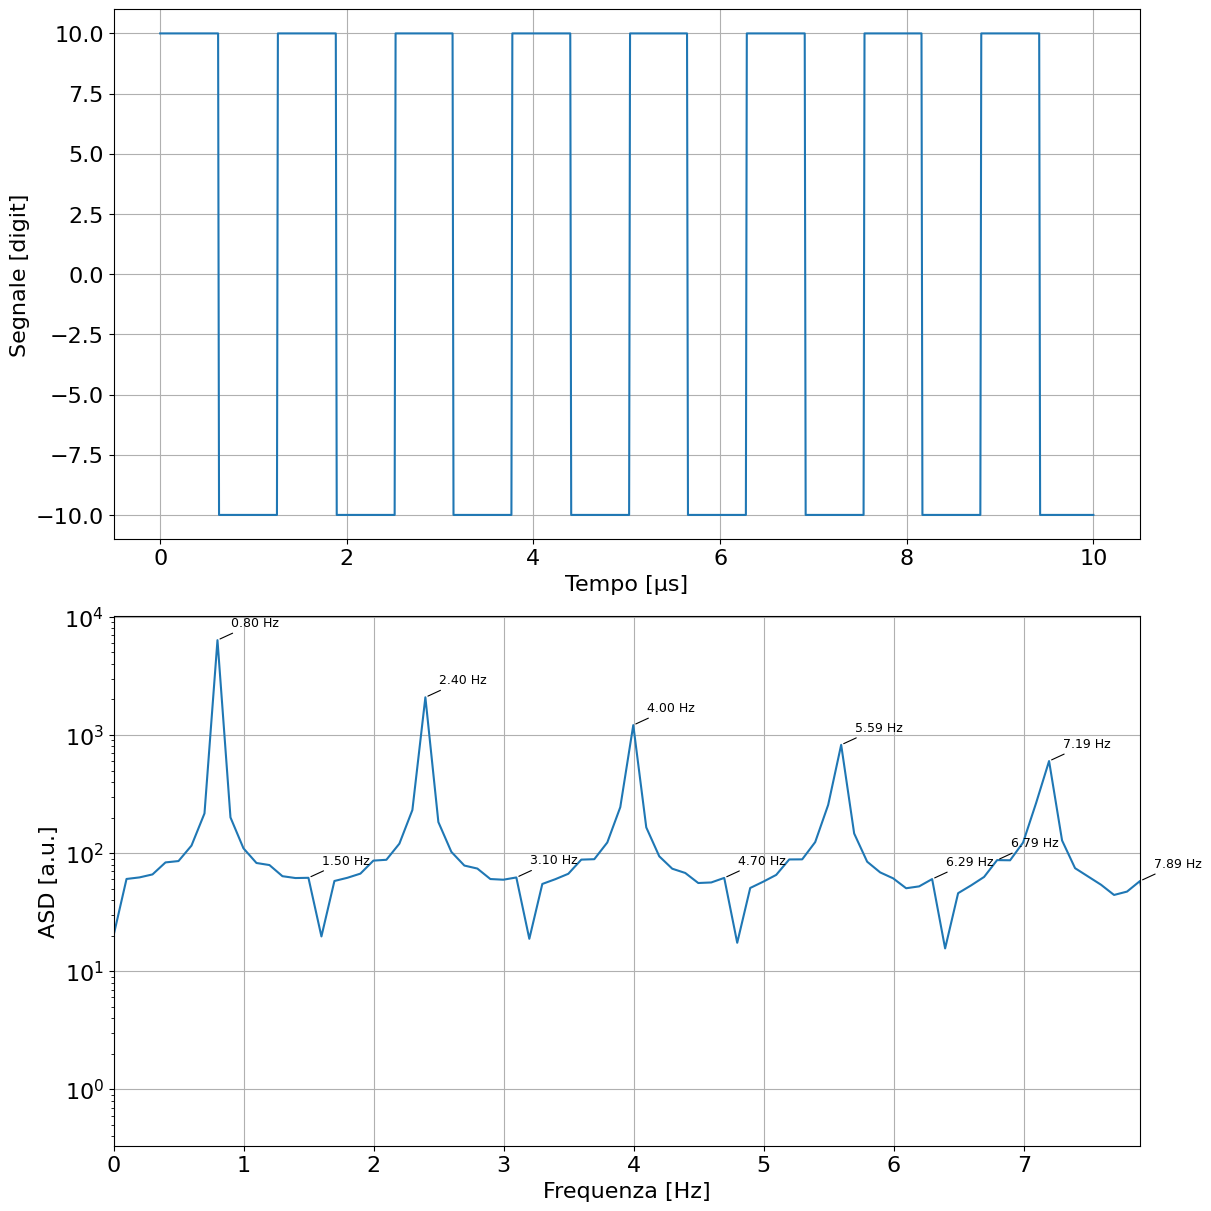

In [ ]:
# Quadra

from scipy import signal

t = np.linspace(0, 10, 1000)
omega = 5
A = 10

V_square = A * signal.square(omega * t)

freq, ASD = do_FFT(t, V_square)
peak_freqs = peaks(freq, ASD)
plot_ASD(t, V_square, freq, ASD, peak_freqs)

**Osservazioni: quadra**

che picchi vede:  
solo le armoniche dispari, f0, 3 f0, 5 f0...  
cioè: 0.8, 2.4, 4.0 ...

ampiezza:  
6300, 2080, 1200...
cioè decresce come 1/n
cioè 2000=6000/3, 1200 = 6000/5...

Peaks: 

0.7992 4031.202601718816
2.3976 444.0658388238748
3.996 157.0112174591086
5.5944 77.82811424656701
7.1928 45.14916055099806
8.7912 28.52708788486651
9.99 2.1338672422385363
10.3896 18.906371387381352
11.5884 2.222707167233842
11.988 12.83284458902127
13.1868 2.2202900388604303
13.4865 9.308806736655859
14.7852 2.1431390746502217
15.084900000000001 8.507293481002739
16.3836 2.0066813050977728
16.6833 7.8316874187413275
17.5824 1.7250676084582466
17.982 1.8253018093801225
18.2817 7.230530203844563
18.6813 1.6798071657543003
19.1808 1.5216934456933318
19.5804 1.6130388853749402
19.8801 6.670404656680307
20.279700000000002 1.4470558410905872
20.7792 1.3408077391973303
21.1788 1.3844267761680633
21.4785 6.13033133581801
21.6783 1.0893614827698166
21.8781 1.2877890025140588
22.3776 1.1884668463897796
22.7772 1.1556770524886812
23.076900000000002 5.598152682213783
23.4765 1.1883033567813208
23.976 1.0686516290558017
24.2757 1.042727482468919
24.6753 5.068061352839196
25.0749 1.130242

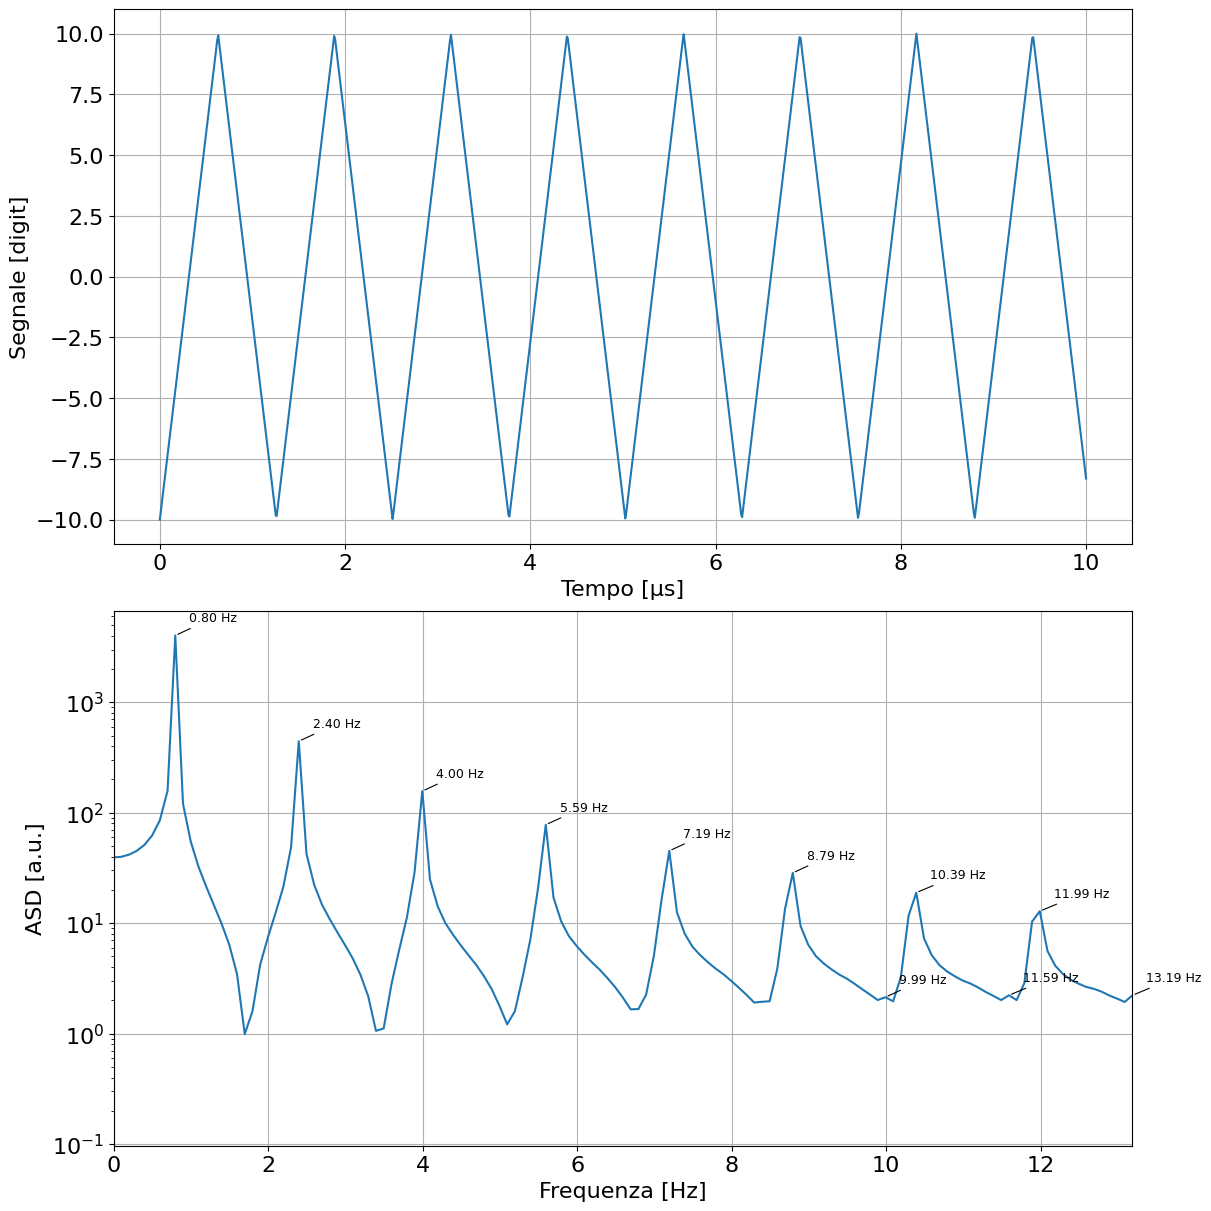

In [ ]:
# Triangolare

t = np.linspace(0, 10, 1000)
omega = 5
A = 10

V_triangle = A * signal.sawtooth(omega * t, width=0.5)

freq, ASD = do_FFT(t, V_triangle)
peak_freqs = peaks(freq, ASD)
plot_ASD(t, V_triangle, freq, ASD, peak_freqs)

**Osservazioni: triangolare**

che picchi vedo: 
solo i dispari, come nella quadra  

ampiezza:  
4000, 444, 157...
cioè: 444=4000/9, 157 = 4000/25
scala come 1/n^2